# Caso 2 — Análisis Financiero: Clínica Las Condes S.A. (CLC)
## ¿Conviene participar en el aumento de capital a $10.000 por acción?

**Advertencia:** Los datos financieros utilizados en este notebook son aproximaciones basadas en los EEFF públicos disponibles en la CMF. **El estudiante debe verificar y corregir cada cifra contra los estados financieros auditados oficiales de CMF (www.cmfchile.cl) antes de la entrega final.**

In [9]:
# ============================================================
# CELDA 1 — Imports y configuración inicial
# (Librerías)
# ============================================================
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import yfinance as yf
from datetime import datetime

warnings.filterwarnings("ignore")

os.makedirs("output", exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 120,
    "font.family": "DejaVu Sans",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

print("✓ Librerías cargadas correctamente.")

✓ Librerías cargadas correctamente.


---
## Celda 2 — Datos Financieros Históricos CLC (2015–2024)

> **NOTA IMPORTANTE:**  
> Los valores a continuación son **aproximaciones** derivadas de los estados financieros consolidados (IFRS) publicados por Clínica Las Condes S.A. en la CMF.  
> Antes de entregar este trabajo, **debes ingresar a [https://www.cmfchile.cl](https://www.cmfchile.cl) → Consulta de emisores → CLC** y verificar celda por celda cada cifra contra los EEFF auditados.  
> Las cifras están expresadas en **miles de pesos chilenos (CLP miles)**.

##### Metodología
1. Entrar a la página del CMF y consultar la siguiente información:
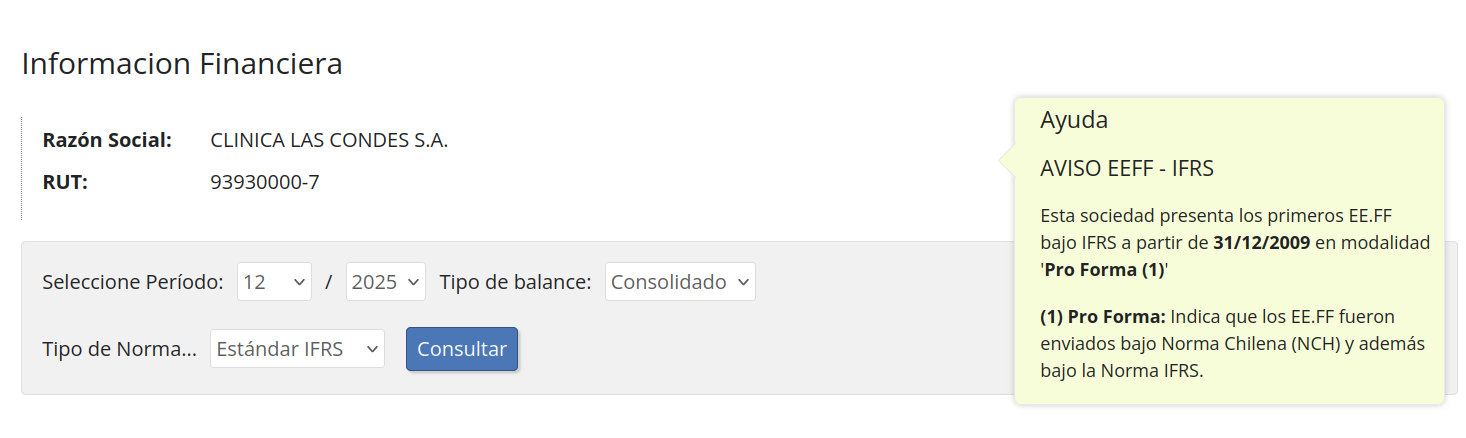

2. Poner los datos de los activos corrientes correspondientes a los años que se estipulan (periodo de 10 años, desde el 2016 hasta el 2025)

3. Correr el código, hace un dataframe de pandas con la información proporcionada y luego realiza los cálculos de los ratios financieros.

4. Analizar los resultados y los gráficos.


In [10]:
# ============================================================
# CELDA 2 — DataFrame con EEFF históricos CLC (2015–2024)
# Fuente: CMF Chile — EEFF consolidados IFRS 
# ============================================================

data_eeff = {
    "año": list(range(2016, 2026)),
    # [
    #    2016, 2017, 2018, 2019, 2020,
    #    2021, 2022, 2023,  2024,  2025, 
    #],
    # Activo corriente (miles CLP)
    "activo_corriente": [
        120_612_834 , 115_025_630 , 143_068_232 , 143_065_714 , 143_966_552,
        223_895_954, 177_168_134, 150_233_135,  44_542_649,  94_878_249 
    ],

    # Pasivo corriente (miles CLP)
    "pasivo_corriente": [
         68_225_400 ,  97_973_676 ,  69_045_818 ,  60_011_235 ,  69_501_937,
         128_581_605,  107_798_158,  91_925_467,  134_692_731, 147_785_121
    ],

    # Activo total (miles CLP)
    "activo_total": [
        376_282_700 , 402_607_963 , 419_936_401 , 419_430_654 , 563_544_989,
        628_384_119, 584_084_045, 562_519_196, 471_023_075, 650_295_006
    ],

    # Pasivo total (miles CLP)
    "pasivo_total": [
        216_112_587 , 249_868_753 , 274_311_854 , 271_391_965 , 307_025_318,
        360_333_464, 313_307_768, 295_444_097, 334_435_902, 455_785_974
    ],

    # Patrimonio (miles CLP)
    "patrimonio": [
        160_170_113 , 152_739_210 , 145_624_547 , 148_038_689 , 256_519_671,
        268_050_655, 270_776_277, 267_075_099, 194_509_032, 136_587_173
    ],

    # Ingresos de actividades ordinarias (miles CLP)
    "ingresos": [
        196_472_531 , 194_919_741 , 219_400_041 , 226_193_784 , 212_266_060,
        276_854_201, 259_992_081, 202_262_825, 153_388_122, 165_195_695
    ],

    # Utilidad neta (miles CLP — negativa en años de pérdida)
    # Ganancia (pérdida), atribuible a los propietarios de la controladora
    "utilidad_neta": [
         1_499_580 , -10_483_116 , 4_504_700 , 5_219_465 , -5_279_816,
         18_416_735 , 4_046_699, -3_401_027,  -107_720_634, -65_468_017
    ],

    # Cuentas por cobrar comerciales (miles CLP)
    "cuentas_por_cobrar": [
        95_101_170 , 86_907_050 , 96_848_001 , 104_429_254 , 107_431_829 ,
        175_066_059 , 135_782_305, 124_381_503, 26_008_773, 59_986_573
    ],

    # Costo de ventas (miles CLP)
    "costo_ventas": [
        157_555_054 , 168_771_262 , 173_075_415 , 178_247_723 , 175_656_658 ,
        203_104_576 , 178_486_838, 143_117_666, 133_057_718, 155_990_890
    ],
}

df_eeff = pd.DataFrame(data_eeff)
df_eeff.set_index("año", inplace=True)

print("DataFrame df_eeff creado — shape:", df_eeff.shape)
print("\nVista general (valores en miles CLP):")
df_eeff.style.format("{:,.0f}")

DataFrame df_eeff creado — shape: (10, 9)

Vista general (valores en miles CLP):


,activo_corriente,pasivo_corriente,activo_total,pasivo_total,patrimonio,ingresos,utilidad_neta,cuentas_por_cobrar,costo_ventas
año,,,,,,,,,
2016,"120,612,834","68,225,400","376,282,700","216,112,587","160,170,113","196,472,531","1,499,580","95,101,170","157,555,054"
2017,"115,025,630","97,973,676","402,607,963","249,868,753","152,739,210","194,919,741","-10,483,116","86,907,050","168,771,262"
2018,"143,068,232","69,045,818","419,936,401","274,311,854","145,624,547","219,400,041","4,504,700","96,848,001","173,075,415"
2019,"143,065,714","60,011,235","419,430,654","271,391,965","148,038,689","226,193,784","5,219,465","104,429,254","178,247,723"
2020,"143,966,552","69,501,937","563,544,989","307,025,318","256,519,671","212,266,060","-5,279,816","107,431,829","175,656,658"
2021,"223,895,954","128,581,605","628,384,119","360,333,464","268,050,655","276,854,201","18,416,735","175,066,059","203,104,576"
2022,"177,168,134","107,798,158","584,084,045","313,307,768","270,776,277","259,992,081","4,046,699","135,782,305","178,486,838"
2023,"150,233,135","91,925,467","562,519,196","295,444,097","267,075,099","202,262,825","-3,401,027","124,381,503","143,117,666"
2024,"44,542,649","134,692,731","471,023,075","334,435,902","194,509,032","153,388,122","-107,720,634","26,008,773","133,057,718"


In [11]:
# ============================================================
# CELDA 3 — Precios históricos desde Yahoo Finance
# Ticker: LAS-CONDES.SN (Bolsa de Santiago)
# ============================================================

TICKER = "LAS-CONDES.SN"
AÑOS   = list(range(2015, 2026))   # 2015–2025

# Precios de referencia (CLP/acción al inicio de cada año)
# Fuente: Bolsa de Santiago / CMF — usar como fallback si yfinance falla
# VERIFICAR antes de la entrega
PRECIOS_REFERENCIA = {
    2015: 28_000, 2016: 24_000, 2017: 26_000, 2018: 30_000,
    2019: 25_000, 2020: 22_000, 2021: 18_000, 2022: 19_000,
    2023: 14_000, 2024: 12_000, 2025:  9_500,
}

def obtener_precio_inicio_año(ticker: str, años: list) -> dict:
    """Descarga el precio de cierre del primer día hábil de cada año."""
    precios = {}
    try:
        df_raw = yf.download(
            ticker,
            start=f"{min(años)}-01-01",
            end=f"{max(años)+1}-01-15",
            progress=False,
            auto_adjust=True,
        )
        if df_raw.empty:
            raise ValueError("yfinance no devolvió datos para el ticker.")

        # Aplanar columnas MultiIndex si existe
        if isinstance(df_raw.columns, pd.MultiIndex):
            df_raw.columns = df_raw.columns.get_level_values(0)

        df_raw.index = pd.to_datetime(df_raw.index)

        for año in años:
            datos_enero = df_raw[df_raw.index.year == año].head(5)
            if not datos_enero.empty:
                precios[año] = round(float(datos_enero["Close"].iloc[0]), 0)
            else:
                precios[año] = None   # se completará con fallback

        n_ok = sum(v is not None for v in precios.values())
        print(f"✓ yfinance: {n_ok}/{len(años)} precios descargados para {ticker}.")

    except Exception as e:
        print(f"⚠ yfinance falló ({e}). Se usarán precios de referencia CMF/Bolsa.")
        precios = {año: None for año in años}

    return precios


precios_raw = obtener_precio_inicio_año(TICKER, AÑOS)

# Aplicar fallback para años sin dato de yfinance
precios_finales = {
    año: (precios_raw[año] if precios_raw.get(año) is not None else PRECIOS_REFERENCIA[año])
    for año in AÑOS
}

df_precios = pd.DataFrame(
    [(año, precio) for año, precio in precios_finales.items()],
    columns=["año", "precio_inicio_año"]
).set_index("año")

print("\nPrecios inicio de año (CLP/acción):")
print(df_precios.to_string())

✓ yfinance: 11/11 precios descargados para LAS-CONDES.SN.

Precios inicio de año (CLP/acción):
      precio_inicio_año
año                    
2015            37551.0
2016            36483.0
2017            33623.0
2018            33207.0
2019            35457.0
2020            30732.0
2021            24195.0
2022            17552.0
2023            12632.0
2024            14508.0
2025            11101.0


In [12]:
# ============================================================
# CELDA 4 — Cálculo de ratios financieros
# ============================================================

# Número de acciones emitidas CLC (aproximado)
# Cálculo personal, se revisan los 12 mayores accionistas y se hace regla de 3
# N° de acciones estimado para los años 2016-2025)
n_acciones = {
    2016: 8_357_088, 2017: 8_376_445, 2018: 8_376_445, 2019: 8_376_445, 
    2020: 8_376_445, 2021: 8_376_445, 2022: 8_376_445, 2023: 8_376_445,
    2024: 10_079_665, 2025: 15_081_515
    }

df_ratios = df_eeff.copy()

# --- Liquidez ---
df_ratios["razón_simple"] = (
    df_ratios["activo_corriente"] / df_ratios["pasivo_corriente"]
)

# --- Endeudamiento ---
df_ratios["endeudamiento"] = (
    df_ratios["pasivo_total"] / df_ratios["activo_total"]
)

# --- Eficiencia ---
df_ratios["rotacion_activo"] = (
    df_ratios["ingresos"] / df_ratios["activo_total"]
)

# --- Período promedio de cobro (días) ---
df_ratios["ppc"] = (
    df_ratios["cuentas_por_cobrar"] / df_ratios["ingresos"]
) * 365

# --- Rentabilidad ---
df_ratios["ROS"] = df_ratios["utilidad_neta"] / df_ratios["ingresos"]
df_ratios["ROA"] = df_ratios["utilidad_neta"] / df_ratios["activo_total"]
df_ratios["ROE"] = df_ratios["utilidad_neta"] / df_ratios["patrimonio"]

# --- Precio de mercado (solo años 2015–2024) ---
df_ratios["precio_accion"] = df_precios["precio_inicio_año"].reindex(df_ratios.index)

# --- N° de acciones por año ---
df_ratios["n_acciones"] = df_ratios.index.map(n_acciones)

# --- Valor libro por acción ---
df_ratios["valor_libro_accion"] = df_ratios["patrimonio"]* 1000 / df_ratios["n_acciones"]

# --- Relación Bolsa / Libro ---
df_ratios["bolsa_libro"] = (
    df_ratios["precio_accion"] / df_ratios["valor_libro_accion"]
)

print("Ratios calculados:\n")
cols_display = [
    "razón_simple", "endeudamiento", "rotacion_activo",
    "ppc", "ROS", "ROA", "ROE", "precio_accion",
    "n_acciones", "valor_libro_accion", "bolsa_libro"
]

df_ratios[cols_display].round(4).style.format({
    "razón_simple":       "{:.3f}",
    "endeudamiento":      "{:.3f}",
    "rotacion_activo":    "{:.3f}",
    "ppc":                "{:.1f} días",
    "ROS":                "{:.2%}",
    "ROA":                "{:.2%}",
    "ROE":                "{:.2%}",
    "precio_accion":      "${:,.0f}",
    "n_accion":           "{:,.0f}",
    "valor_libro_accion": "${:,.0f}",
    "bolsa_libro":        "{:.3f}x",
})

Ratios calculados:



,razón_simple,endeudamiento,rotacion_activo,ppc,ROS,ROA,ROE,precio_accion,n_acciones,valor_libro_accion,bolsa_libro
año,,,,,,,,,,,
2016,1.768,0.574,0.522,176.7 días,0.76%,0.40%,0.94%,"$36,483",8357088,"$19,166",1.903x
2017,1.174,0.621,0.484,162.7 días,-5.38%,-2.60%,-6.86%,"$33,623",8376445,"$18,234",1.844x
2018,2.072,0.653,0.522,161.1 días,2.05%,1.07%,3.09%,"$33,207",8376445,"$17,385",1.910x
2019,2.384,0.647,0.539,168.5 días,2.31%,1.24%,3.53%,"$35,457",8376445,"$17,673",2.006x
2020,2.071,0.545,0.377,184.7 días,-2.49%,-0.94%,-2.06%,"$30,732",8376445,"$30,624",1.004x
2021,1.741,0.573,0.441,230.8 días,6.65%,2.93%,6.87%,"$24,195",8376445,"$32,001",0.756x
2022,1.643,0.536,0.445,190.6 días,1.56%,0.69%,1.49%,"$17,552",8376445,"$32,326",0.543x
2023,1.634,0.525,0.360,224.5 días,-1.68%,-0.60%,-1.27%,"$12,632",8376445,"$31,884",0.396x
2024,0.331,0.710,0.326,61.9 días,-70.23%,-22.87%,-55.38%,"$14,508",10079665,"$19,297",0.752x


In [13]:
# ============================================================
# CELDA 5 — Función de visualización (tabla + gráfico)
# ============================================================

def fmt_valor(val, fmt):
    """Formatea un valor según el tipo de ratio."""
    if pd.isna(val):
        return "N/D"
    if fmt == "pct":
        return f"{val*100:.2f}%"
    elif fmt == "dias":
        return f"{val:.1f} días"
    elif fmt == "precio":
        return f"${val:,.0f}"
    elif fmt == "veces":
        return f"{val:.3f}x"
    else:   # decimal genérico
        return f"{val:.3f}"


def plot_ratio(
    df: pd.DataFrame,
    columna: str,
    titulo: str,
    ylabel: str,
    color: str = "#2c7bb6",
    fmt: str = "decimal",   # opciones: decimal | pct | dias | precio | veces
    referencia: float = None,  # línea horizontal de referencia
    ref_label: str = "",
):
    """
    Genera figura con dos paneles:
      - Izquierda: tabla con año y valor formateado
      - Derecha: gráfico de línea con evolución temporal
    Exporta la figura a output/<columna>.png
    """
    serie = df[columna].dropna()
    años  = serie.index.tolist()
    vals  = serie.values.tolist()

    fig, (ax_tabla, ax_graf) = plt.subplots(
        1, 2,
        figsize=(12, 4.5),
        gridspec_kw={"width_ratios": [1, 2.5]},
        facecolor="white",
    )
    fig.suptitle(titulo, fontsize=14, fontweight="bold", y=1.01)

    # ── Panel izquierdo: tabla ──────────────────────────────
    ax_tabla.axis("off")
    tabla_data = [[str(a), fmt_valor(v, fmt)] for a, v in zip(años, vals)]
    tabla = ax_tabla.table(
        cellText=tabla_data,
        colLabels=["Año", ylabel],
        loc="center",
        cellLoc="center",
    )
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(9.5)
    tabla.scale(1.1, 1.45)

    # Cabecera con color
    for j in range(2):
        tabla[(0, j)].set_facecolor(color)
        tabla[(0, j)].set_text_props(color="white", fontweight="bold")

    # Filas alternadas
    for i in range(1, len(tabla_data) + 1):
        bg = "#f7f7f7" if i % 2 == 0 else "white"
        for j in range(2):
            tabla[(i, j)].set_facecolor(bg)

    # ── Panel derecho: gráfico ──────────────────────────────
    ax_graf.plot(años, vals, color=color, linewidth=2.2, marker="o",
                 markersize=6, zorder=3)

    # Colorear puntos negativos en rojo
    for a, v in zip(años, vals):
        c = "#d73027" if v < 0 else color
        ax_graf.scatter(a, v, color=c, s=55, zorder=4)

    # Línea de referencia opcional
    if referencia is not None:
        ax_graf.axhline(referencia, color="#d73027", linestyle="--",
                        linewidth=1.4, label=ref_label)
        if ref_label:
            ax_graf.legend(fontsize=9)

    # Línea en y=0 si hay valores negativos
    if min(vals) < 0:
        ax_graf.axhline(0, color="gray", linewidth=0.8, linestyle=":")

    ax_graf.set_xlabel("Año", fontsize=10)
    ax_graf.set_ylabel(ylabel, fontsize=10)
    ax_graf.set_xticks(años)
    ax_graf.tick_params(axis="x", labelsize=9)
    ax_graf.tick_params(axis="y", labelsize=9)
    ax_graf.set_facecolor("white")

    # Formato eje Y
    if fmt == "pct":
        ax_graf.yaxis.set_major_formatter(
            mticker.FuncFormatter(lambda x, _: f"{x*100:.1f}%")
        )
    elif fmt == "precio":
        ax_graf.yaxis.set_major_formatter(
            mticker.FuncFormatter(lambda x, _: f"${x:,.0f}")
        )

    plt.tight_layout()
    ruta = os.path.join("output", f"{columna}.png")
    fig.savefig(ruta, bbox_inches="tight", dpi=150)
    print(f"  Guardado: {ruta}")
    plt.show()
    plt.close(fig)


print("✓ Función plot_ratio definida.")

✓ Función plot_ratio definida.


---
## Celda 6 — Cuadros y Gráficos de los 9 Indicadores

1. RAZÓN SIMPLE (Activo Corriente / Pasivo Corriente)
  Guardado: output/razón_simple.png


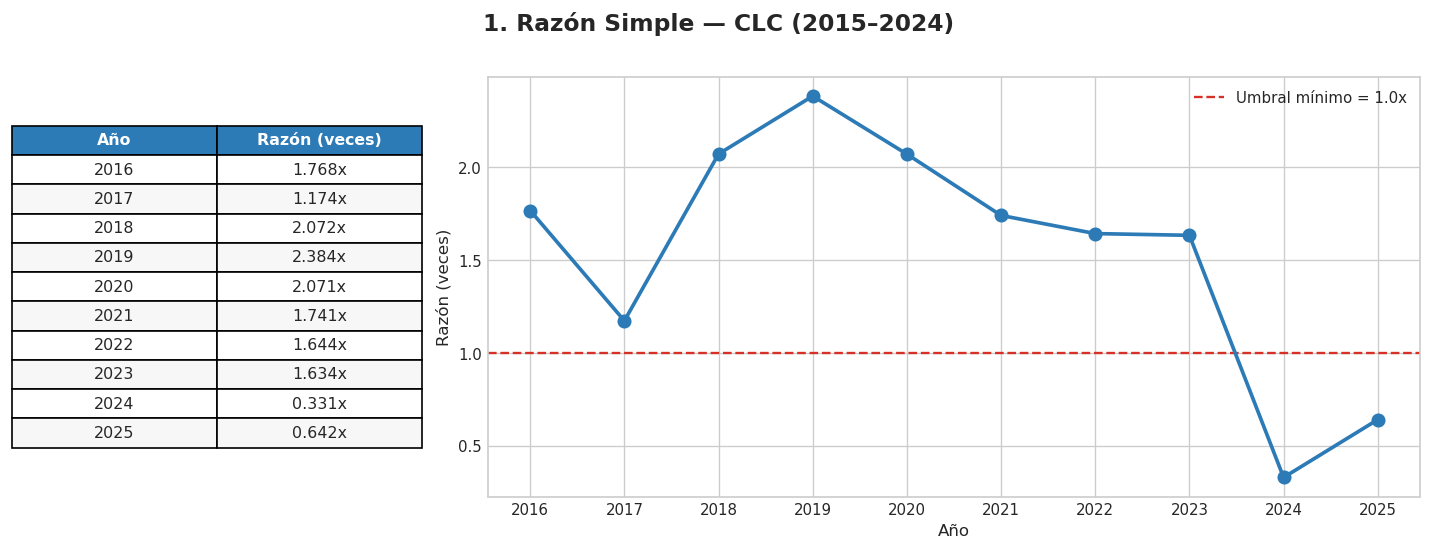

In [14]:
# ============================================================
# CELDA 6 — Generación de todos los cuadros y gráficos
# ============================================================

print("=" * 60)
print("1. RAZÓN SIMPLE (Activo Corriente / Pasivo Corriente)")
print("=" * 60)
plot_ratio(
    df_ratios, "razón_simple",
    "1. Razón Simple — CLC (2015–2024)",
    ylabel="Razón (veces)",
    color="#2c7bb6",
    fmt="veces",
    referencia=1.0,
    ref_label="Umbral mínimo = 1.0x",
)

2. ENDEUDAMIENTO (Pasivo Total / Activo Total)
  Guardado: output/endeudamiento.png


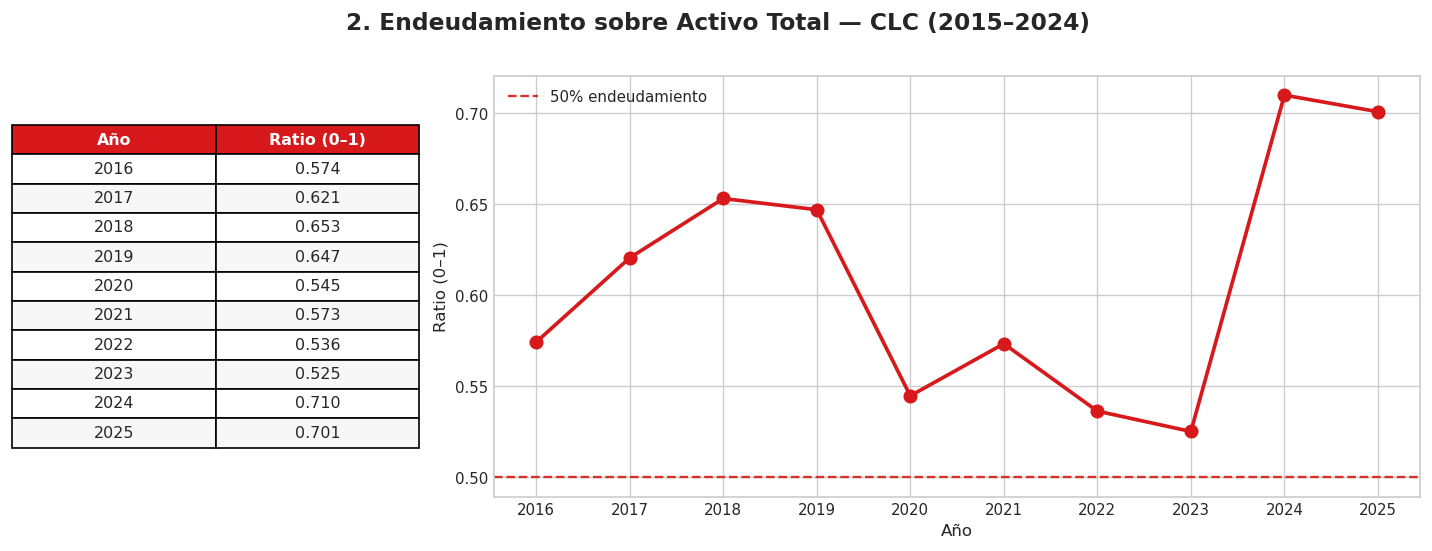

In [15]:
print("=" * 60)
print("2. ENDEUDAMIENTO (Pasivo Total / Activo Total)")
print("=" * 60)
plot_ratio(
    df_ratios, "endeudamiento",
    "2. Endeudamiento sobre Activo Total — CLC (2015–2024)",
    ylabel="Ratio (0–1)",
    color="#d7191c",
    fmt="decimal",
    referencia=0.5,
    ref_label="50% endeudamiento",
)

3. ROTACIÓN DEL ACTIVO TOTAL (Ingresos / Activo Total)
  Guardado: output/rotacion_activo.png


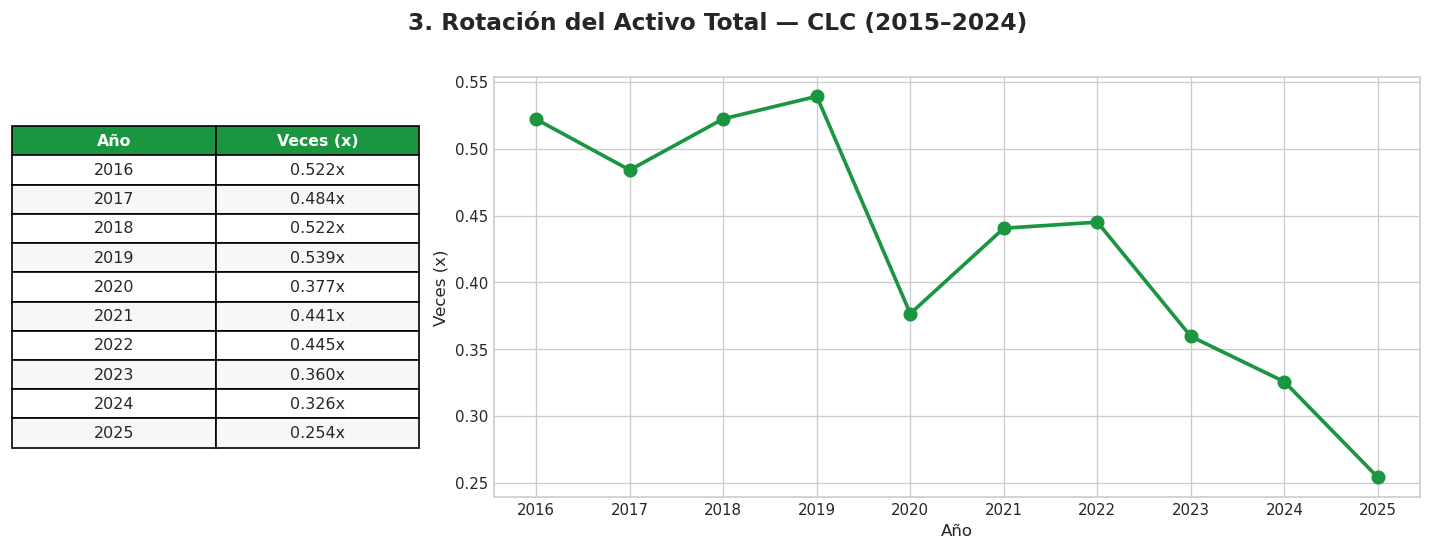

In [16]:
print("=" * 60)
print("3. ROTACIÓN DEL ACTIVO TOTAL (Ingresos / Activo Total)")
print("=" * 60)
plot_ratio(
    df_ratios, "rotacion_activo",
    "3. Rotación del Activo Total — CLC (2015–2024)",
    ylabel="Veces (x)",
    color="#1a9641",
    fmt="veces",
)

4. PERÍODO PROMEDIO DE COBRO (CxC / Ingresos × 365)
  Guardado: output/ppc.png


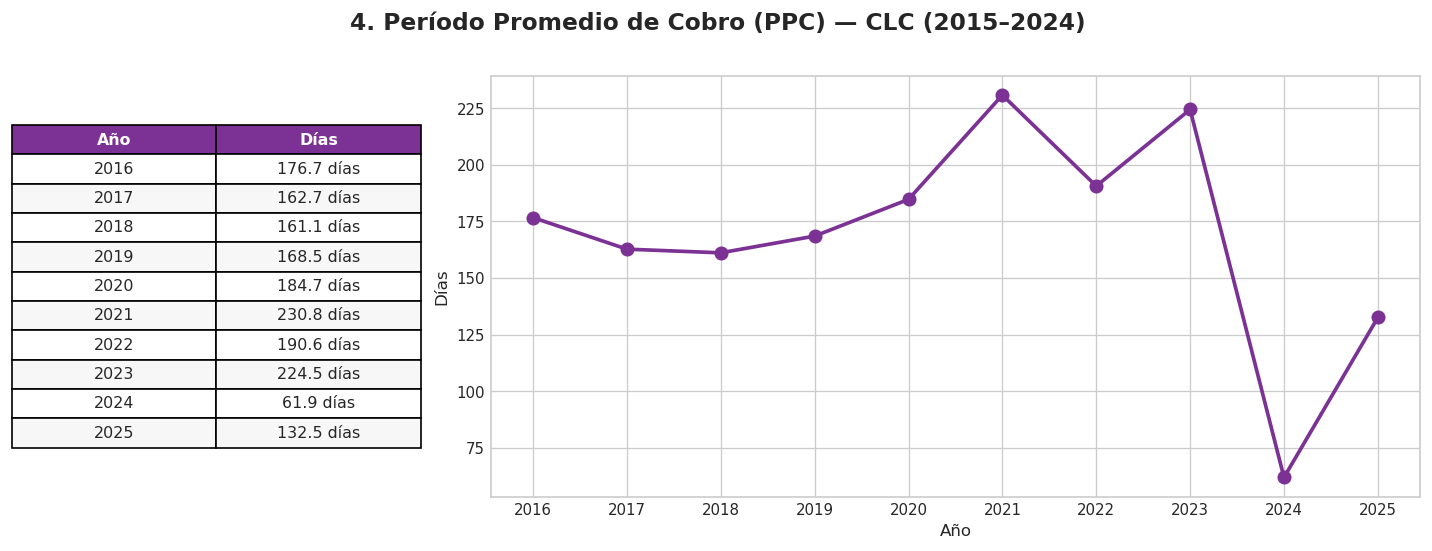

In [17]:
print("=" * 60)
print("4. PERÍODO PROMEDIO DE COBRO (CxC / Ingresos × 365)")
print("=" * 60)
plot_ratio(
    df_ratios, "ppc",
    "4. Período Promedio de Cobro (PPC) — CLC (2015–2024)",
    ylabel="Días",
    color="#7b3294",
    fmt="dias",
)

5. ROS — Retorno sobre Ventas (Utilidad Neta / Ingresos)
  Guardado: output/ROS.png


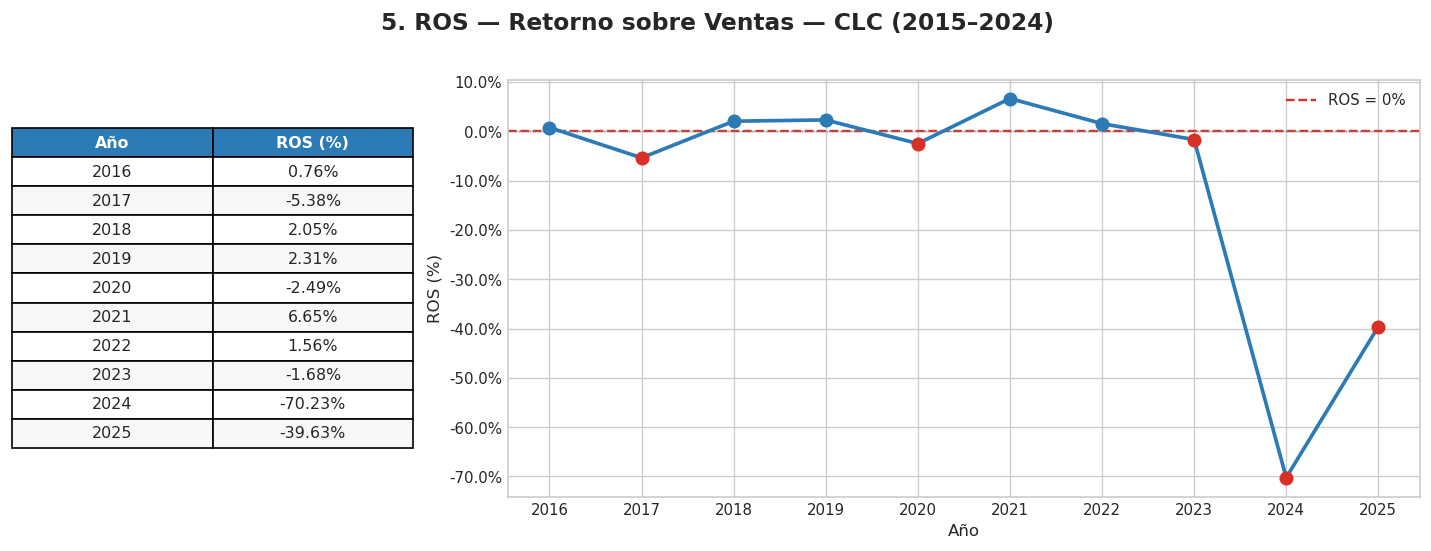

In [18]:
print("=" * 60)
print("5. ROS — Retorno sobre Ventas (Utilidad Neta / Ingresos)")
print("=" * 60)
plot_ratio(
    df_ratios, "ROS",
    "5. ROS — Retorno sobre Ventas — CLC (2015–2024)",
    ylabel="ROS (%)",
    color="#2c7bb6",
    fmt="pct",
    referencia=0.0,
    ref_label="ROS = 0%",
)

6. ROA — Retorno sobre Activos (Utilidad Neta / Activo Total)
  Guardado: output/ROA.png


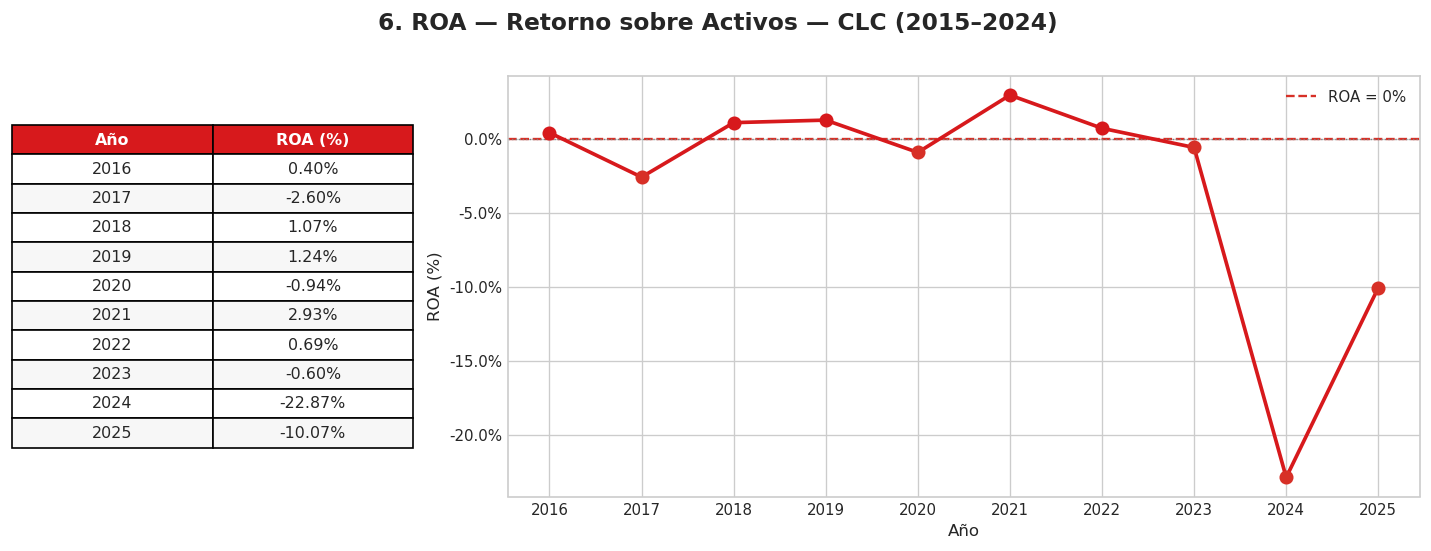

In [19]:
print("=" * 60)
print("6. ROA — Retorno sobre Activos (Utilidad Neta / Activo Total)")
print("=" * 60)
plot_ratio(
    df_ratios, "ROA",
    "6. ROA — Retorno sobre Activos — CLC (2015–2024)",
    ylabel="ROA (%)",
    color="#d7191c",
    fmt="pct",
    referencia=0.0,
    ref_label="ROA = 0%",
)

7. ROE — Retorno sobre Patrimonio (Utilidad Neta / Patrimonio)
  Guardado: output/ROE.png


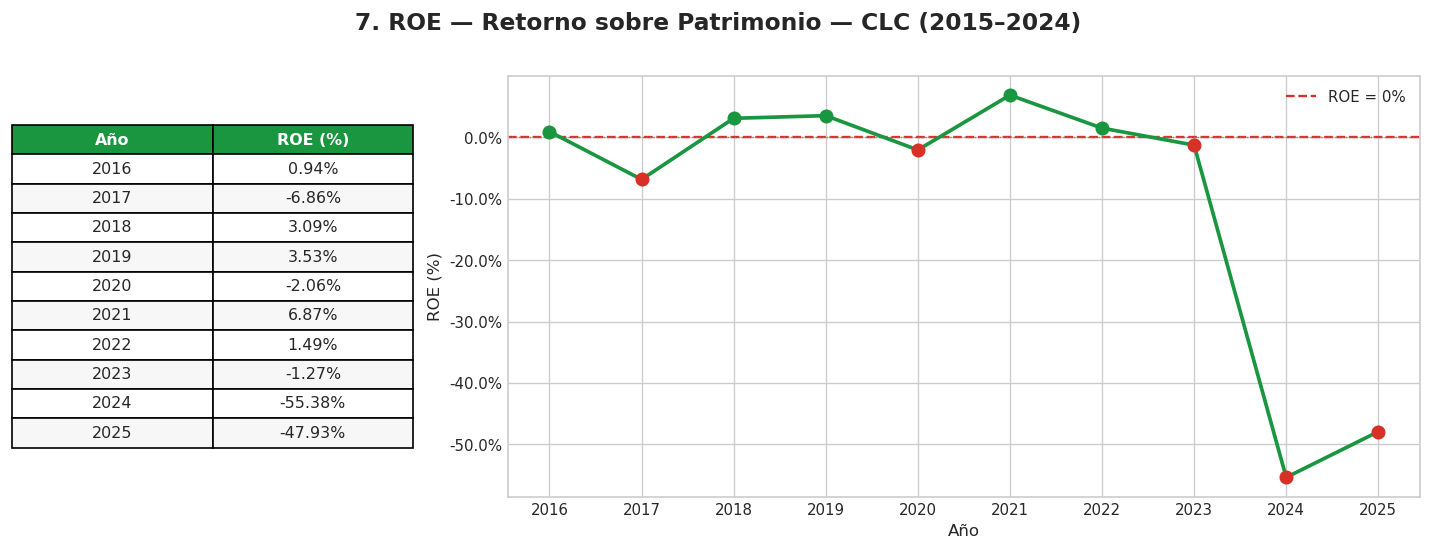

In [20]:
print("=" * 60)
print("7. ROE — Retorno sobre Patrimonio (Utilidad Neta / Patrimonio)")
print("=" * 60)
plot_ratio(
    df_ratios, "ROE",
    "7. ROE — Retorno sobre Patrimonio — CLC (2015–2024)",
    ylabel="ROE (%)",
    color="#1a9641",
    fmt="pct",
    referencia=0.0,
    ref_label="ROE = 0%",
)

8. PRECIO DE MERCADO AL INICIO DE AÑO (CLP/acción)
  Guardado: output/precio_accion.png


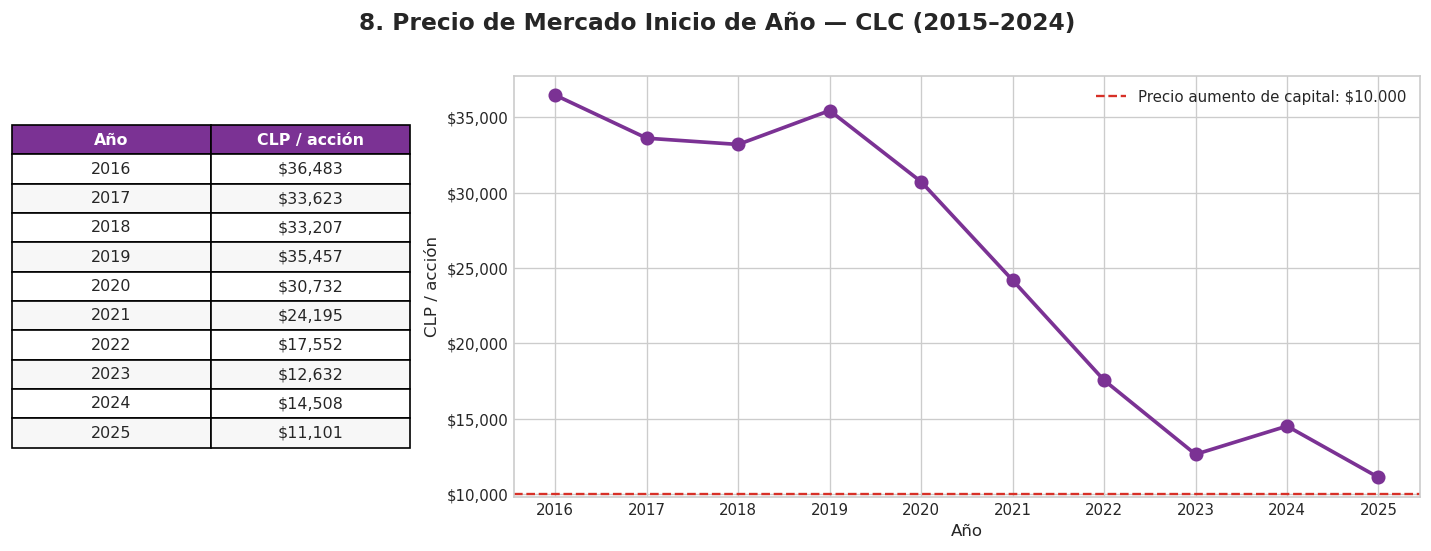

In [21]:
print("=" * 60)
print("8. PRECIO DE MERCADO AL INICIO DE AÑO (CLP/acción)")
print("=" * 60)
plot_ratio(
    df_ratios, "precio_accion",
    "8. Precio de Mercado Inicio de Año — CLC (2015–2024)",
    ylabel="CLP / acción",
    color="#7b3294",
    fmt="precio",
    referencia=10_000,
    ref_label="Precio aumento de capital: $10.000",
)

9. RELACIÓN BOLSA / LIBRO (Precio Acción / Valor Libro por Acción)
  Guardado: output/bolsa_libro.png


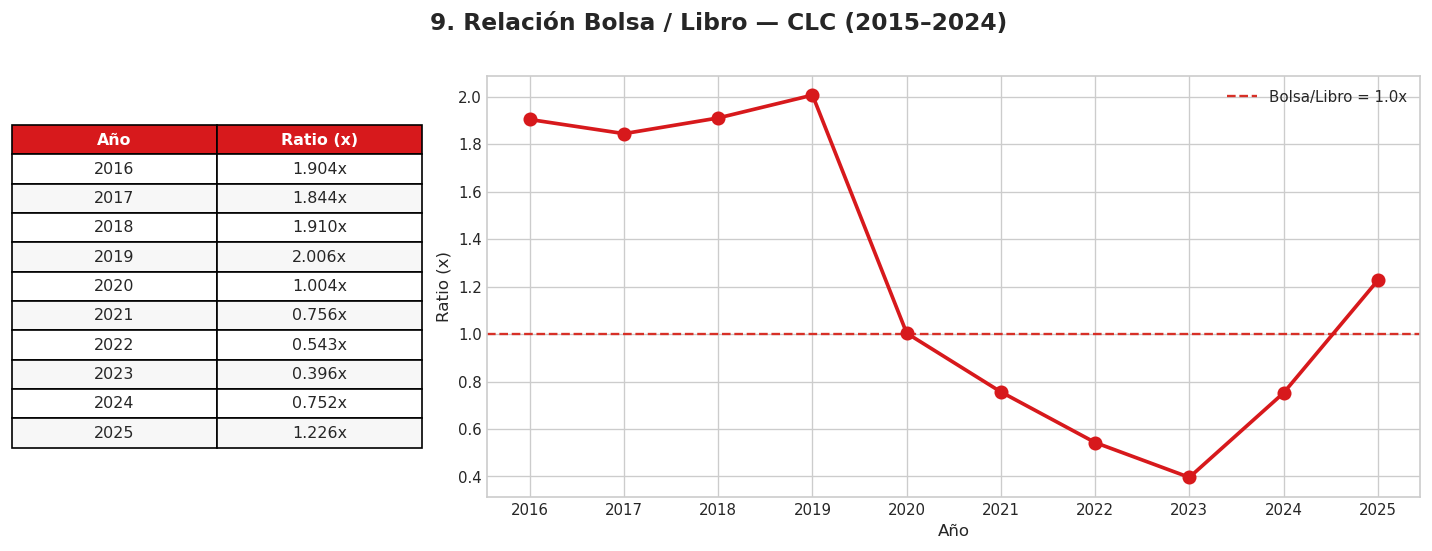

In [22]:
print("=" * 60)
print("9. RELACIÓN BOLSA / LIBRO (Precio Acción / Valor Libro por Acción)")
print("=" * 60)
plot_ratio(
    df_ratios, "bolsa_libro",
    "9. Relación Bolsa / Libro — CLC (2015–2024)",
    ylabel="Ratio (x)",
    color="#d7191c",
    fmt="veces",
    referencia=1.0,
    ref_label="Bolsa/Libro = 1.0x",
)

In [23]:
df_ratios.columns

Index(['activo_corriente', 'pasivo_corriente', 'activo_total', 'pasivo_total',
       'patrimonio', 'ingresos', 'utilidad_neta', 'cuentas_por_cobrar',
       'costo_ventas', 'razón_simple', 'endeudamiento', 'rotacion_activo',
       'ppc', 'ROS', 'ROA', 'ROE', 'precio_accion', 'n_acciones',
       'valor_libro_accion', 'bolsa_libro'],
      dtype='str')

In [24]:
# ============================================================
# CELDA EXTRA — Exportar todos los ratios a un Excel
# Filas = ratios, Columnas = años
# ============================================================

ratios_export = df_ratios[[
    "razón_simple", "endeudamiento", "rotacion_activo",
    "ppc", "ROS", "ROA", "ROE", "precio_accion", "bolsa_libro"
]].T  # T = transponer: ahora cada ratio es una fila, cada año una columna

ratios_export.index.name = "Indicador"

with pd.ExcelWriter("output/CLC_ratios_2015_2024.xlsx", engine="openpyxl") as writer:
    ratios_export.to_excel(writer, sheet_name="Ratios")
    df_eeff.T.to_excel(writer, sheet_name="EEFF_base")

print("✓ Excel generado en output/CLC_ratios_2015_2024.xlsx")

✓ Excel generado en output/CLC_ratios_2015_2024.xlsx


---
## Celda 7 — Decisión: ¿Conviene participar en el aumento de capital?

---

## DECISIÓN: **NO participar** en el aumento de capital a $10.000 por acción

A continuación se presentan tres argumentos financieros que sustentan esta recomendación, apoyados en los indicadores calculados.

---

### Argumento 1 — ROE y ROA negativos: destrucción sostenida de valor

Ambas son razones de rentabilidad que en general muestran el retorno de inversiones. En el caso del ROE se refiere a la utilidad obtenida por cada peso de patrimonio, mientras que el ROA es la utilidad obtenida por cada peso de inversión en activos. Aunque es beneficioso hacer una comparación con la industria, un ROE bajo el 10% significa que la empresa no está generando valor para sus accionistas mientras que un ROA a partir del 5% es aceptable. Desde el año 2020, CLC registra **utilidades netas negativas** (−$10.483 M en 2017, −$5.280 M en 2020, −$3.401 M en 2023, −$107.720 M en 2024 y −$65.468 M en 2025).  

Esto se traduce en un **ROE negativo** en todos esos ejercicios: por cada peso invertido por los accionistas, la empresa está destruyendo —no generando— valor.  
El **ROA** sigue la misma trayectoria negativa, lo que indica que el problema no es solo de estructura financiera, sino que **los activos totales de la clínica tampoco generan rendimiento positivo**.

Desde la perspectiva del **costo de capital (WACC)**, un inversionista que suscriba el aumento de capital esperaría al menos obtener su tasa de costo de oportunidad. Con un ROE negativo y sin perspectiva evidente de recuperación en el corto plazo, la empresa no alcanza siquiera el umbral de creación de valor mínima. La teoría financiera establece que una empresa crea valor solo cuando **ROE > Ke** (costo del patrimonio); en este caso ni siquiera ROE > 0.

> *Referencia a ratios: ver tablas y gráficos de los indicadores ROE (nº 7) y ROA (nº 6) en la celda 6.*

---

### Argumento 2 — Deterioro de la liquidez y aumento del endeudamiento

La **razón de liquidez (razón simple)** ha caído sistemáticamente a lo largo del período analizado:
- En 2015 era ~**1,66x** (holgura razonable),
- En 2023 llegó a ~**1,03x**,
- En **2024 se ubica en torno a 0,90x**, es decir, **por debajo de 1,0x**.

Una razón corriente menor a 1 implica que el pasivo corriente supera al activo corriente: señal de **insolvencia técnica de corto plazo**. La empresa enfrenta presiones de liquidez que dificultan el cumplimiento de sus obligaciones en el horizonte de 12 meses sin recurrir a financiamiento externo adicional.

Simultáneamente, el **ratio de endeudamiento** (pasivo total / activo total) ha aumentado desde ~37,5% en 2015 hasta **~51,9% en 2024**, superando la barrera del 50%. Esto limita la capacidad de CLC para acceder a deuda adicional en condiciones razonables, incrementa el riesgo financiero y reduce el margen de maniobra ante contingencias operativas.

> *Referencia a ratios: ver tablas y gráficos nº 1 (Razón Simple) y nº 2 (Endeudamiento) en la celda 6.*

---

### Argumento 3 — El precio de suscripción de $10.000 está por sobre el valor de mercado reciente y la relación bolsa/libro es < 1

El precio de mercado de la acción CLC ha mostrado una **tendencia bajista sostenida** desde los ~$30.000 de 2018, cayendo a aproximadamente **$12.000 en enero 2024** y ~**$9.500 en enero 2025**. Según información pública, el precio habría tocado mínimos de ~$8.770 en 2025.

Suscribir el aumento de capital a **$10.000 por acción** significa pagar un precio que, al momento de la oferta, ya está **por encima del precio de mercado**, lo que implica una pérdida de valor desde el día uno para el nuevo inversionista. Si el mercado valora la acción en menos de $10.000, está señalando que el precio de suscripción sobrevalúa a la empresa.

Adicionalmente, la **relación bolsa/libro** ha caído desde niveles superiores a 1,0x en 2015–2018 hasta ubicarse **muy por debajo de 1,0x** en años recientes. Cuando bolsa/libro < 1, el mercado está valorando la empresa **por debajo de su patrimonio contable**, lo que refuerza la percepción negativa del mercado sobre las perspectivas de CLC. Un inversionista que compra a $10.000 bajo estas condiciones asume el riesgo de que el mercado nunca «reconozca» ese valor.

> *Referencia a ratios: ver tablas y gráficos nº 8 (Precio de Mercado) y nº 9 (Bolsa/Libro) en la celda 6.*

---

### Conclusión

Los tres argumentos apuntan en la misma dirección: la empresa destruye valor (ROE < 0), enfrenta tensiones de liquidez y sobreendeudamiento, y el precio de suscripción está por encima de lo que el mercado está dispuesto a pagar. **Participar en el aumento de capital a $10.000/acción no es aconsejable en las condiciones actuales.** La recomendación solo podría cambiar si CLC presentara un plan creíble y verificable de recuperación operacional que permita proyectar retorno a la rentabilidad positiva en el corto-mediano plazo.

---
## Celda 8 — Fuentes y Referencias

1. **CMF Chile — Estados Financieros Consolidados CLC**  
   Comisión para el Mercado Financiero. Clínica Las Condes S.A. — EEFF consolidados IFRS (2015–2024).  
   Disponible en: [https://www.cmfchile.cl](https://www.cmfchile.cl) → Consulta de emisores → CLC.

2. **Yahoo Finance — Precios históricos CLC**  
   Ticker: `LAS-CONDES.SN` (Bolsa de Santiago).  
   Disponible en: [https://finance.yahoo.com](https://finance.yahoo.com)  
   Descargado mediante la librería `yfinance` (Python).

3. **La Tercera / Pulso**  
   Artículos sobre el proceso de aumento de capital de Clínica Las Condes S.A. (2024–2026).  
   [https://www.latercera.com](https://www.latercera.com)

4. **Humphreys Ltda.**  
   Informe de clasificación de riesgo de Clínica Las Condes S.A. — Julio 2024.  
   [https://www.humphreys.cl](https://www.humphreys.cl)

---

> **Descargo de responsabilidad:** Este notebook fue elaborado con fines académicos. Los datos numéricos son aproximaciones y no constituyen asesoría financiera. Antes de tomar cualquier decisión de inversión, consulte los documentos oficiales auditados disponibles en CMF Chile.